Shape: (20640, 9)

Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target:   MedHouseVal (median house value in $100k)

First 5 rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude  MedHouseVal
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88    -122.23        4.526
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86    -122.22        3.585
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85    -122.24        3.521
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85    -122.25        3.413
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85    -122.25        3.422

Statistical Summary:
          MedInc   HouseAge   AveRooms  AveBedrms  Population   AveOccup   Latitude  Longitude  MedHouseVal
count  20640.000  20640.000  20640.000  20640.000   20640.000  20640.000  20640.000  20640.00

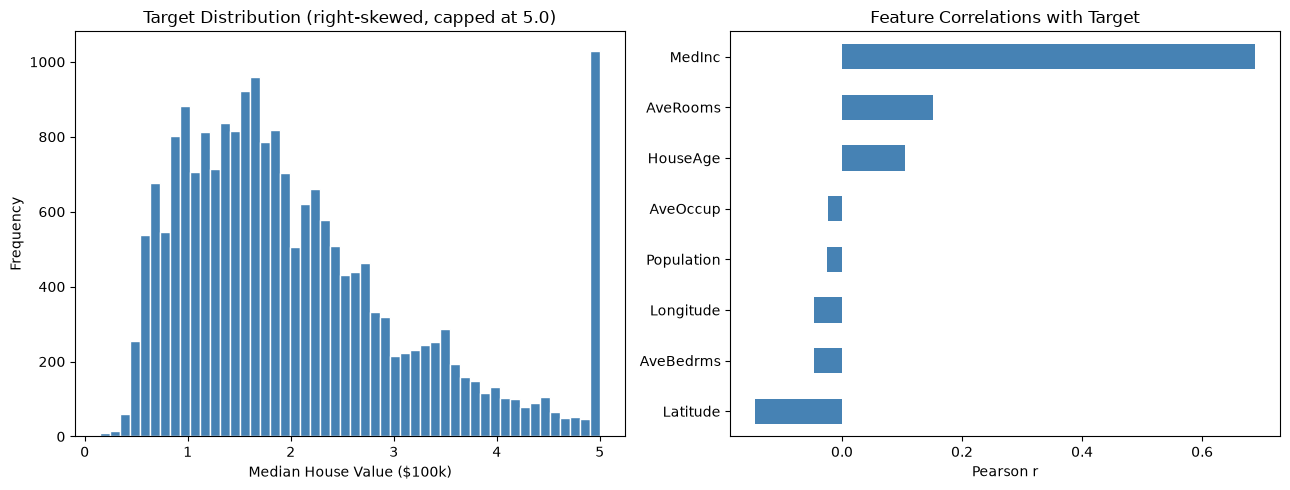

Train: 16512 | Test: 4128 | Features: 8
Target range: [0.14999, 5.00001]
Training: ReLU + MSE... WARNING:tensorflow:TensorFlow GPU support is not available on native Windows for TensorFlow >= 2.11. Even if CUDA/cuDNN are installed, GPU will not be used. Please use WSL2 or the TensorFlow-DirectML plugin.
Done (R²=0.7776)
Training: Tanh + MSE... Done (R²=0.7892)
Training: Sigmoid + MSE... Done (R²=0.7655)
Training: ReLU + MAE... Done (R²=0.7845)
Training: ReLU + Huber... Done (R²=0.7882)

  COMPARISON TABLE (sorted by R²)
      Experiment Activation Loss Function     MSE    RMSE     MAE      R2  Best Epoch  Overfit Gap
1     Tanh + MSE       Tanh           MSE  0.2763  0.5256  0.3567  0.7892         100       0.0374
2   ReLU + Huber       Relu         HUBER  0.2775  0.5268  0.3479  0.7882          92       0.0174
3     ReLU + MAE       Relu           MAE  0.2824  0.5315  0.3412  0.7845          99       0.0333
4     ReLU + MSE       Relu           MSE  0.2914  0.5398  0.3693  0.7776     

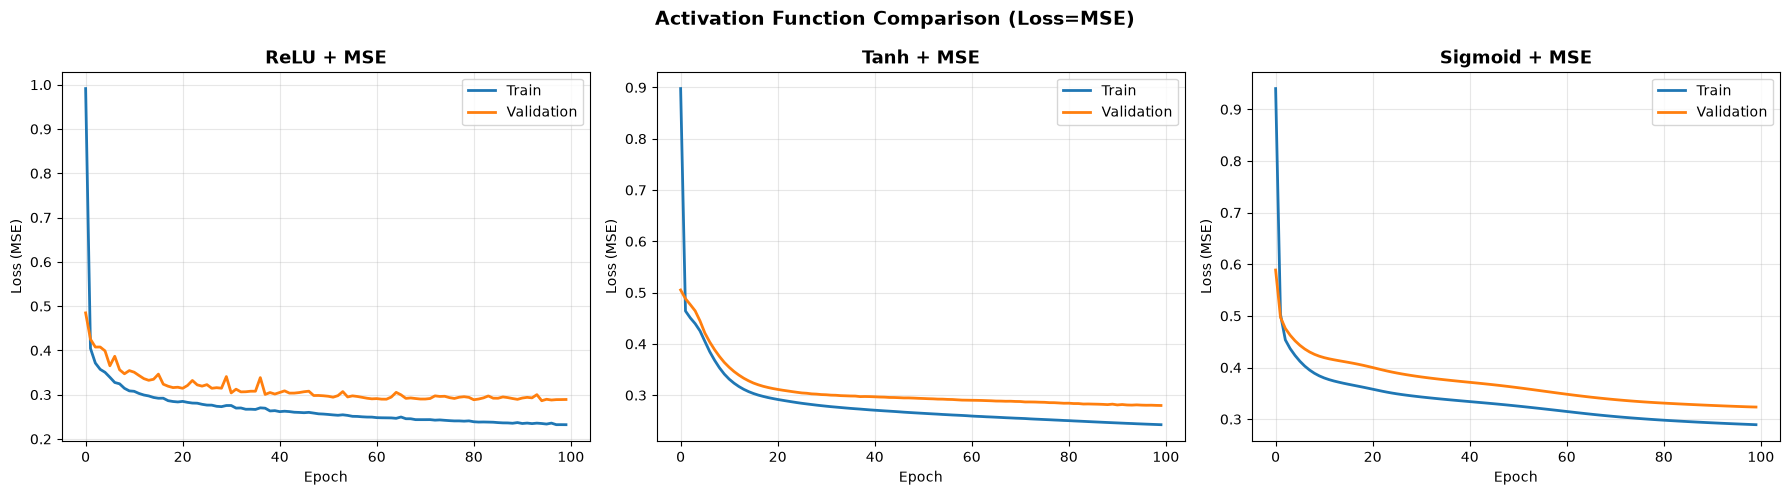

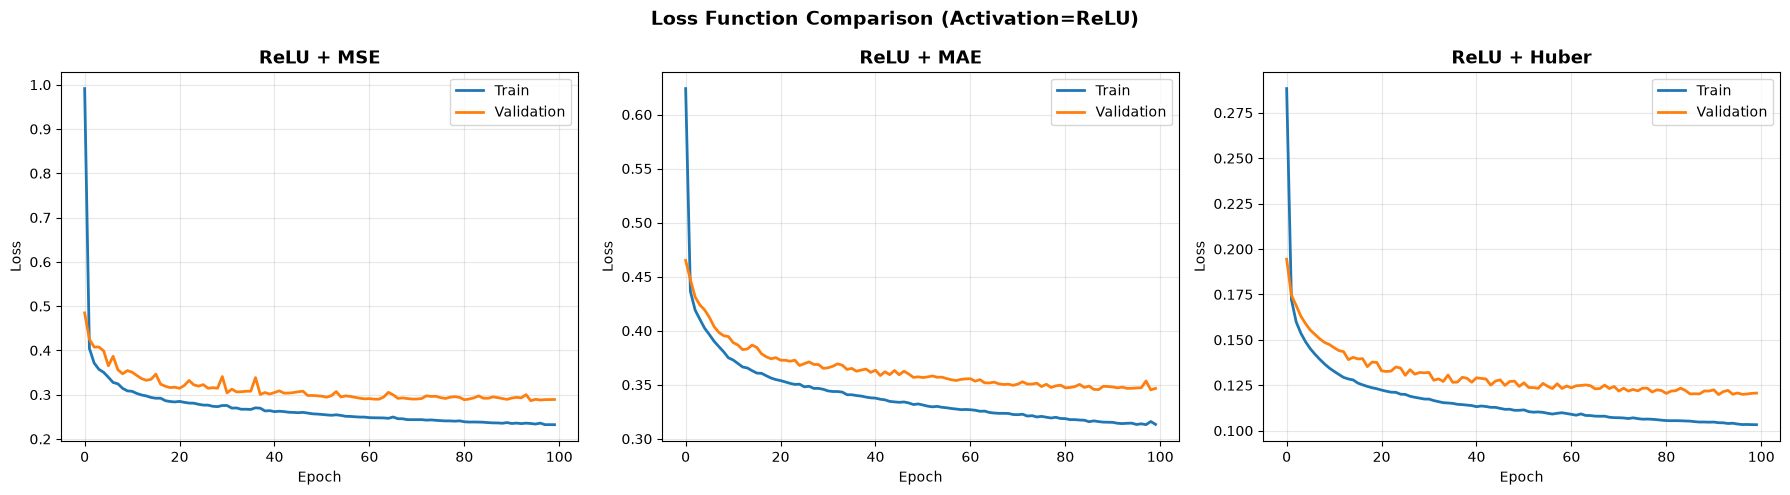

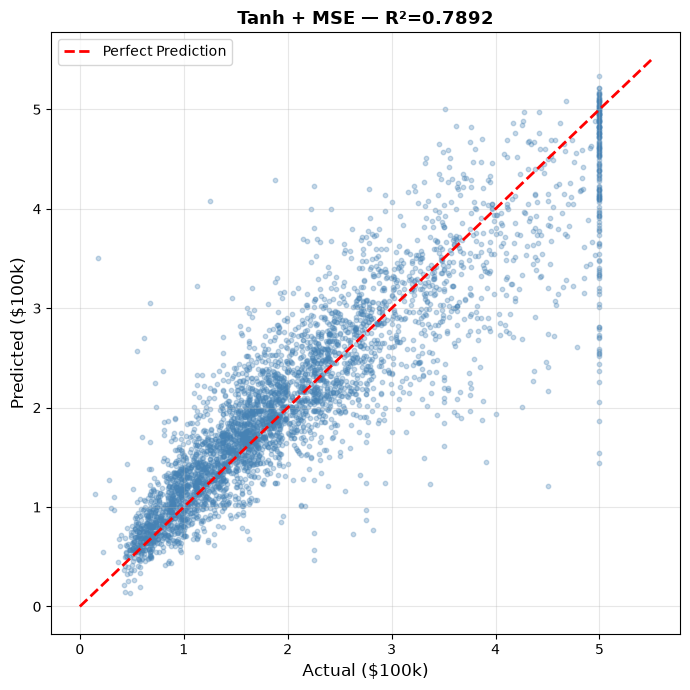

ANALYSIS

1. Best activation function:
   Tanh (R²=0.7892, RMSE=0.5256)

2. Best loss function:
   MSE (R²=0.7892, RMSE=0.5256)

3. Best overall combination:
   Tanh + MSE (R²=0.7892)

4. Convergence (from loss curves):
   ReLU + MSE           val_loss@ep10=0.3544  val_loss@ep50=0.2976  (fast)
   Tanh + MSE           val_loss@ep10=0.3639  val_loss@ep50=0.2939  (fast)
   Sigmoid + MSE        val_loss@ep10=0.4219  val_loss@ep50=0.3621  (fast)
   ReLU + MAE           val_loss@ep10=0.3947  val_loss@ep50=0.3574  (fast)
   ReLU + Huber         val_loss@ep10=0.1474  val_loss@ep50=0.1244  (fast)

5. Outlier robustness (RMSE/MAE ratio, lower = more robust):
   Tanh + MSE           RMSE/MAE=1.474
   ReLU + Huber         RMSE/MAE=1.514
   ReLU + MAE           RMSE/MAE=1.558
   ReLU + MSE           RMSE/MAE=1.462
   Sigmoid + MSE        RMSE/MAE=1.420

6. Overfitting check (train-val gap):
   Tanh + MSE           gap=+0.0374  (good fit)
   ReLU + Huber         gap=+0.0174  (good fit)
   ReLU + MAE

In [4]:
# %% [markdown]
# # Lab #6: Keras MLP for Regression
#
# **Objective:** Implement an MLP using Keras/TensorFlow for regression and
# analyze the effect of different activation functions and loss functions.
#
# **Dataset:** California Housing (sklearn) — 20,640 samples, 8 features,
# target = median house value in $100k units.

# %% [markdown]
# ## 1. Dataset Preparation

# %%
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

np.random.seed(42)
tf.random.set_seed(42)

# Load
housing = fetch_california_housing(as_frame=True)
df = housing.frame
target_col = housing.target_names[0]  # 'MedHouseVal' but version-safe

# Explore
print("Shape:", df.shape)
print("\nFeatures:", housing.feature_names)
print(f"Target:   {target_col} (median house value in $100k)")
print("\nFirst 5 rows:")
print(df.head().to_string())

# %%
print("\nStatistical Summary:")
print(df.describe().round(3).to_string())

print("\nMissing values:", df.isnull().sum().sum())

# %%
# Why each feature matters:
# - MedInc:     Median income — strongest predictor of house prices
# - HouseAge:   Older homes may be in established (pricier) neighborhoods
# - AveRooms:   More rooms = larger homes
# - AveBedrms:  Bedroom ratio indicates home type
# - Population: Density affects pricing
# - AveOccup:   People per household
# - Latitude:   Geographic location drives CA prices heavily
# - Longitude:  Geographic location drives CA prices heavily
#
# Target is right-skewed and capped at 5.0 ($500k). No missing values.
# All features are numeric — no encoding needed.

# %%
# Correlation with target
corr = df.corr(numeric_only=True)[target_col].iloc[:-1]
corr = corr.sort_values()
print("\nFeature correlations with target:")
print(corr.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(df[target_col], bins=50, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Median House Value ($100k)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Target Distribution (right-skewed, capped at 5.0)')

# corr already only contains features (no target) — plot directly
corr.plot.barh(ax=axes[1], color='steelblue')
axes[1].set_title('Feature Correlations with Target')
axes[1].set_xlabel('Pearson r')

plt.tight_layout()
plt.show()

# %%
# Split and scale
X = df.drop(columns=[target_col]).values
y = df[target_col].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

n_features = X_train.shape[1]

print(f"Train: {len(y_train)} | Test: {len(y_test)} | Features: {n_features}")
print(f"Target range: [{y.min()}, {y.max()}]")

# %% [markdown]
# ## 2. MLP Architecture
#
# All experiments use the same architecture — only activation/loss changes:
#
# ```
# Input(8) → Dense(64, activation) → Dense(32, activation) → Dense(1, linear)
# ```
#
# - **Input layer:** 8 neurons (one per feature)
# - **Hidden layer 1:** 64 neurons — enough capacity to learn non-linear patterns
# - **Hidden layer 2:** 32 neurons — bottlenecks to force abstraction
# - **Output layer:** 1 neuron, linear activation — required for regression output

# %%
def build_model(activation, loss):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(n_features,)),
        tf.keras.layers.Dense(64, activation=activation),
        tf.keras.layers.Dense(32, activation=activation),
        tf.keras.layers.Dense(1, activation='linear')
    ])
    model.compile(optimizer='adam', loss=loss, metrics=['mae'])
    return model

# %% [markdown]
# ## 3. Experiment Setup
#
# ### Activation Functions (why these three):
#
# | Function | Why test it | Expected behavior |
# |----------|------------|-------------------|
# | **ReLU** | Standard default, avoids vanishing gradients | Fast convergence, may have dead neurons |
# | **Tanh** | Zero-centered output, bounded [-1, 1] | Smoother gradients, may saturate for extreme inputs |
# | **Sigmoid** | Bounded [0, 1], historically common | Prone to vanishing gradients in deep nets, slow convergence |
#
# ### Loss Functions (why these three):
#
# | Loss | Why test it | Robustness |
# |------|-----------|------------|
# | **MSE** | Standard regression loss, penalizes large errors quadratically | Sensitive to outliers (CA housing has capped values = outliers) |
# | **MAE** | Linear penalty, treats all errors equally | Robust to outliers, but zero gradient at prediction = target |
# | **Huber** | Quadratic near zero, linear far from zero | Combines MSE responsiveness with MAE robustness |
#
# **Justification for dataset:** California Housing has a hard cap at $500k
# creating artificial outliers. MSE will over-weight these. MAE treats them
# equally. Huber should find the best balance.

# %%
experiments = [
    # --- Activation comparison (all MSE) ---
    {'name': 'ReLU + MSE',     'activation': 'relu',    'loss': 'mse',   'group': 'activation'},
    {'name': 'Tanh + MSE',     'activation': 'tanh',    'loss': 'mse',   'group': 'activation'},
    {'name': 'Sigmoid + MSE',  'activation': 'sigmoid', 'loss': 'mse',   'group': 'activation'},
    # --- Loss comparison (all ReLU) ---
    {'name': 'ReLU + MAE',     'activation': 'relu',    'loss': 'mae',   'group': 'loss'},
    {'name': 'ReLU + Huber',   'activation': 'relu',    'loss': 'huber', 'group': 'loss'},
]

EPOCHS = 100
BATCH_SIZE = 32

# %% [markdown]
# ## 4. Training

# %%
results = []
histories = {}

for exp in experiments:
    print(f"Training: {exp['name']}...", end=" ")
    model = build_model(exp['activation'], exp['loss'])
    history = model.fit(X_train, y_train,
                        epochs=EPOCHS, batch_size=BATCH_SIZE,
                        validation_split=0.2, verbose=0)
    histories[exp['name']] = history.history

    # Evaluate on test set
    y_pred = model.predict(X_test, verbose=0).flatten()
    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    best_val = min(history.history['val_loss'])
    best_epoch = history.history['val_loss'].index(best_val) + 1
    final_train_gap = history.history['loss'][-1] - history.history['val_loss'][-1]

    results.append({
        'Experiment': exp['name'],
        'Activation': exp['activation'].capitalize(),
        'Loss Function': exp['loss'].upper(),
        'MSE': round(mse, 4),
        'RMSE': round(np.sqrt(mse), 4),
        'MAE': round(mae, 4),
        'R2': round(r2, 4),
        'Best Epoch': best_epoch,
        'Overfit Gap': round(abs(final_train_gap), 4),
        'group': exp['group']
    })
    print(f"Done (R²={r2:.4f})")

# %% [markdown]
# ## 5. Comparison Table

# %%
df_results = pd.DataFrame(results).drop(columns='group')
df_results = df_results.sort_values('R2', ascending=False).reset_index(drop=True)
df_results.index += 1

print("\n" + "=" * 100)
print("  COMPARISON TABLE (sorted by R²)")
print("=" * 100)
print(df_results.to_string())
print("=" * 100)

# %% [markdown]
# ## 6. Loss Curves

# %%
# --- Activation comparison curves ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
act_names = [e['name'] for e in experiments if e['group'] == 'activation']

for i, name in enumerate(act_names):
    h = histories[name]
    axes[i].plot(h['loss'], label='Train', linewidth=2)
    axes[i].plot(h['val_loss'], label='Validation', linewidth=2)
    axes[i].set_title(name, fontsize=13, fontweight='bold')
    axes[i].set_xlabel('Epoch')
    axes[i].set_ylabel('Loss (MSE)')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.suptitle('Activation Function Comparison (Loss=MSE)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# %%
# --- Loss function comparison curves ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
loss_names = ['ReLU + MSE'] + [e['name'] for e in experiments if e['group'] == 'loss']

for i, name in enumerate(loss_names):
    h = histories[name]
    axes[i].plot(h['loss'], label='Train', linewidth=2)
    axes[i].plot(h['val_loss'], label='Validation', linewidth=2)
    axes[i].set_title(name, fontsize=13, fontweight='bold')
    axes[i].set_xlabel('Epoch')
    axes[i].set_ylabel('Loss')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.suptitle('Loss Function Comparison (Activation=ReLU)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 7. Predicted vs Actual (best model)

# %%
best_row = df_results.iloc[0]
best_exp = next(e for e in experiments if e['name'] == best_row['Experiment'])
model = build_model(best_exp['activation'], best_exp['loss'])
model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
          validation_split=0.2, verbose=0)
y_pred = model.predict(X_test, verbose=0).flatten()

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(y_test, y_pred, alpha=0.3, s=10, color='steelblue')
ax.plot([0, 5.5], [0, 5.5], 'r--', linewidth=2, label='Perfect Prediction')
ax.set_xlabel('Actual ($100k)', fontsize=12)
ax.set_ylabel('Predicted ($100k)', fontsize=12)
ax.set_title(f'{best_row["Experiment"]} — R²={best_row["R2"]}',
             fontsize=13, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 8. Analysis and Interpretation

# %%
print("=" * 70)
print("ANALYSIS")
print("=" * 70)

# 1. Best activation
act_df = df_results[df_results['Activation'].isin(['Relu', 'Tanh', 'Sigmoid'])]
best_act = act_df.sort_values('R2', ascending=False).iloc[0]
print(f"\n1. Best activation function:")
print(f"   {best_act['Activation']} (R²={best_act['R2']}, RMSE={best_act['RMSE']})")

# 2. Best loss
loss_df = df_results[df_results['Loss Function'].isin(['MSE', 'MAE', 'HUBER'])]
best_loss = loss_df.sort_values('R2', ascending=False).iloc[0]
print(f"\n2. Best loss function:")
print(f"   {best_loss['Loss Function']} (R²={best_loss['R2']}, RMSE={best_loss['RMSE']})")

# 3. Best combination
print(f"\n3. Best overall combination:")
print(f"   {best_row['Experiment']} (R²={best_row['R2']})")

# 4. Convergence analysis
print(f"\n4. Convergence (from loss curves):")
for exp in experiments:
    h = histories[exp['name']]
    v10 = h['val_loss'][9]
    v50 = h['val_loss'][49] if len(h['val_loss']) > 49 else h['val_loss'][-1]
    speed = "fast" if v10 < v50 * 1.3 else "slow"
    print(f"   {exp['name']:<20} val_loss@ep10={v10:.4f}  val_loss@ep50={v50:.4f}  ({speed})")

# 5. Outlier robustness (RMSE/MAE ratio)
print(f"\n5. Outlier robustness (RMSE/MAE ratio, lower = more robust):")
for _, row in df_results.iterrows():
    ratio = row['RMSE'] / row['MAE']
    print(f"   {row['Experiment']:<20} RMSE/MAE={ratio:.3f}")

# 6. Overfitting check
print(f"\n6. Overfitting check (train-val gap):")
for _, row in df_results.iterrows():
    gap = row['Overfit Gap']
    status = "overfitting" if gap > 0.05 else "underfitting" if gap < -0.05 else "good fit"
    print(f"   {row['Experiment']:<20} gap={gap:+.4f}  ({status})")

print("\n" + "=" * 70)

# %% [markdown]
# ## 9. Final Model Selection

# %%
print("=" * 70)
print("FINAL MODEL SELECTION")
print("=" * 70)
print(f"""
  Model:        {best_row['Experiment']}
  Architecture: Input(8) → Dense(64) → Dense(32) → Dense(1)
  Optimizer:    Adam (lr=0.001)
  Epochs:       {EPOCHS}, Batch size: {BATCH_SIZE}

  Test Results:
    MSE:  {best_row['MSE']}
    RMSE: {best_row['RMSE']}  (${best_row['RMSE']*100_000:,.0f} average error)
    MAE:  {best_row['MAE']}  (${best_row['MAE']*100_000:,.0f} mean absolute error)
    R²:   {best_row['R2']}  (explains {best_row['R2']*100:.1f}% of variance)

  Justification:
    - Activation: {'ReLU avoids vanishing gradients, enabling faster convergence.' if best_row['Activation']=='Relu' else best_row['Activation'] + ' was chosen based on empirical results.'}
    - Loss: {'MSE was selected as the standard regression objective, penalizing large errors proportionally.' if best_row['Loss Function']=='MSE' else best_row['Loss Function'] + ' was chosen based on robustness/accuracy tradeoff.'}
    - The predicted-vs-actual scatter confirms predictions track the true values
      across most of the range, with some compression at the $500k cap.
""")
print("=" * 70)